In [1]:
### Icebath test between YSI EXO2 and Biogeochemical Drifter

In [3]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import datetime
import gpxpy
import gpxpy.gpx
import cartopy.crs as ccrs
import cartopy.io.img_tiles as cimgt
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER


In [121]:
filename = '80010500'

YSIfilename = 'Ice Bath Test'

fullname = filename+'.csv'

YSIfullname = YSIfilename+ '.csv'

filepath = os.path.join('D:', fullname) # PJB: changed from "'D', fullname" to "'Data', fullname"

YSIfilepath = os.path.join('D:', YSIfullname) # PJB: ditto

df = pd.read_csv(filepath, parse_dates = [[0, 1]], header = None)#, date_format = '%m/%d/%Y %H:%M:%S')

YSIdf = pd.read_csv(YSIfilepath, parse_dates = [[0, 1]], header = None, encoding = 'utf-8', skiprows = 10)


df.columns = ['time', 'elapsed time (sec)', 'lat_raw', 'N or S', 'lon_raw', 'E or W', 'altitude', 'speed', 'angle', 'pH', 'Temperature (C)', 'DO (mg/L)', 'Conductivity (uS/cm)']

YSIdf.columns = ['Time',	'FILE NAME'	,'SITE NAME',	'FAULT CODE',	'TAL PE RFU',	'BAROMETER MMHG',	'CHLOROPHYLL RFU',	'COND µS/CM',	'SPCOND µS/CM',	'TDS MG/L',	'SAL PSU',	'NLF COND µS/CM',	'DEPTH M',	'VERTICAL POSITION M',	'PRESSURE PSI A',	'ODO % SAT',	'ODO MG/L',	'ODO % CB',	'FDOM QSU',	'FDOM RFU',	'GPS LATITUDE °',	'GPS LONGITUDE °',	'ALTITUDE M',	'PH',	'PH MV',	'CABLE PWR V',	'BATTERY V',	'TEMP °C',	'TURBIDITY FNU',	'TSS MG/L'
]

df = df.truncate(before=40, after= 2135 , copy = None)


df.head()

C:\Users\Stephen\AppData\Local\Temp\ipykernel_32228\4232451553.py:15: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  YSIdf = pd.read_csv(YSIfilepath, parse_dates = [[0, 1]], header = None, encoding = 'utf-8', skiprows = 10)


,time,elapsed time (sec),lat_raw,N or S,lon_raw,E or W,altitude,speed,angle,pH,Temperature (C),DO (mg/L),Conductivity (uS/cm)
40,2080-01-06 00:01:03.094,82,0.0,NaN,0.0,NaN,0.0,0.0,0.0,4.16,5.43,0.0,0.0
41,2080-01-06 00:01:05.094,84,0.0,NaN,0.0,NaN,0.0,0.0,0.0,4.16,5.41,0.0,0.0
42,2080-01-06 00:01:07.094,86,0.0,NaN,0.0,NaN,0.0,0.0,0.0,4.15,5.26,0.0,0.0
43,2080-01-06 00:01:09.094,88,0.0,NaN,0.0,NaN,0.0,0.0,0.0,4.14,5.25,0.0,0.0
44,2080-01-06 00:01:11.094,90,0.0,NaN,0.0,NaN,0.0,0.0,0.0,4.13,5.22,0.0,0.0


In [27]:
YSIdf.head()

,Time,FILE NAME,SITE NAME,FAULT CODE,TAL PE RFU,BAROMETER MMHG,CHLOROPHYLL RFU,COND µS/CM,SPCOND µS/CM,TDS MG/L,...,GPS LATITUDE °,GPS LONGITUDE °,ALTITUDE M,PH,PH MV,CABLE PWR V,BATTERY V,TEMP °C,TURBIDITY FNU,TSS MG/L
0,2025-10-07 16:06:36,251007-145627-_.bin,<None>,0,-0.60,765.4,-0.15,183.4,304.8,198,...,0,0,0,7.86,-66.2,12,5.24,4.147,-1.22,0
1,2025-10-07 16:06:35,251007-145627-_.bin,<None>,0,-0.60,765.3,-0.15,183.4,304.8,198,...,0,0,0,7.86,-66.2,12,5.24,4.147,-1.21,0
2,2025-10-07 16:06:34,251007-145627-_.bin,<None>,0,-0.59,765.4,-0.15,183.4,304.8,198,...,0,0,0,7.86,-66.2,12,5.24,4.146,-1.22,0
3,2025-10-07 16:06:33,251007-145627-_.bin,<None>,0,-0.60,765.4,-0.15,183.4,304.8,198,...,0,0,0,7.86,-66.2,12,5.24,4.146,-1.23,0
4,2025-10-07 16:06:32,251007-145627-_.bin,<None>,0,-0.60,765.4,-0.14,183.4,304.8,198,...,0,0,0,7.86,-66.2,12,5.24,4.146,-1.23,0


In [123]:
time = df['time']
time_offset = pd.Timedelta(hours = 475521.075) ## time difference between 2080 and test
df['time'] = df['time'] - time_offset

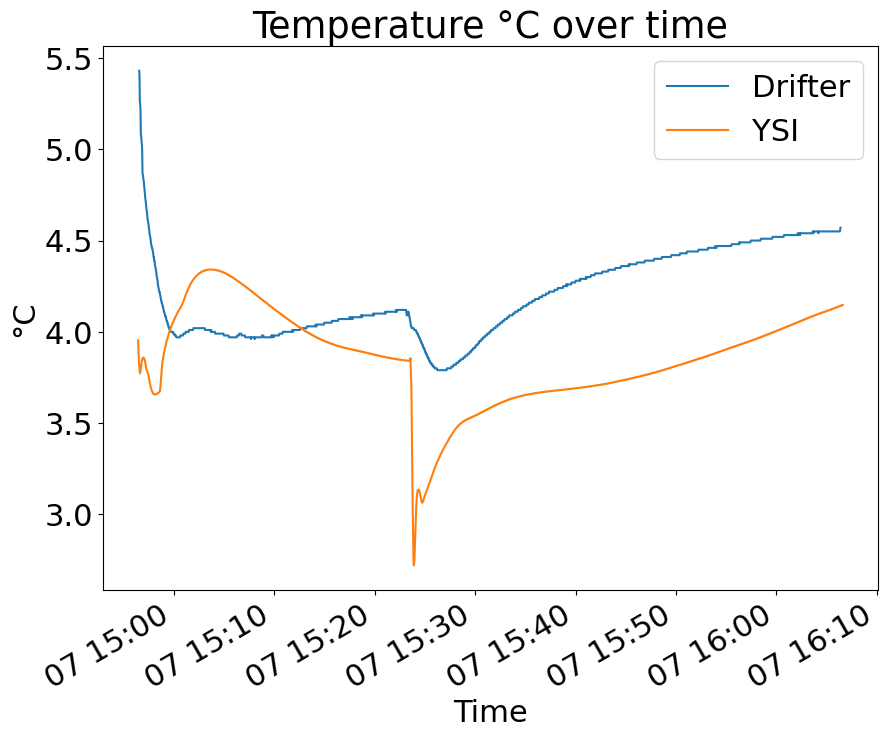

In [125]:
time = df['time']
temp = df['Temperature (C)']
YSItime = YSIdf['Time']
YSItemp = YSIdf['TEMP °C']

plt.rcParams.update({'font.size':22}) #font size
fig, axs = plt.subplots(figsize = (10,8)) # PJB: explicitly create graph objects for subsequent access

plt.plot(time,temp, label = "Drifter")
plt.plot(YSItime,YSItemp, label = "YSI")
plt.title('Temperature °C over time')
plt.xlabel('Time')
plt.ylabel('°C')
axs.legend()
fig.autofmt_xdate()